# 01 - Exploratory Data Analysis

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning
**Dataset:** PhiUSIIL Phishing URL Dataset (UCI Machine Learning Repository, 2024)
**Objective:** Understand the structure, quality and class balance of the dataset before preprocessing.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/PhiUSIIL_Phishing_URL_Dataset.csv")
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

Rows: 235,795 | Columns: 56


## 1. Dataset Overview

In [3]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.000,1.000,0.523,0.062,3,1,0,0,0.000,18,0.581,0,0.000,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000,0.000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.000,0.667,0.033,0.050,2,1,0,0,0.000,9,0.391,0,0.000,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.556,55.556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.000,0.867,0.029,0.064,2,2,0,0,0.000,15,0.517,0,0.000,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.667,46.667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.000,1.000,0.523,0.058,3,1,0,0,0.000,13,0.500,0,0.000,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000,0.000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.000,1.000,0.080,0.059,3,1,0,0,0.000,20,0.606,0,0.000,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000,100.000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [5]:
text_cols = df.select_dtypes(include="str").columns.tolist()
print(f"Text columns ({len(text_cols)}): {text_cols}")

Text columns (5): ['FILENAME', 'URL', 'Domain', 'TLD', 'Title']


## 2. Data Quality Check

In [6]:
missing = df.isnull().sum()
print(f"Total missing values: {missing.sum()}")
missing[missing > 0]

Total missing values: 0


Series([], dtype: int64)

In [7]:
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates}")

Duplicate rows: 0


In [8]:
duplicate_urls = df["URL"].duplicated().sum()
print(f"Duplicate URLs: {duplicate_urls}")

Duplicate URLs: 425


In [9]:
dup_mask = df["URL"].duplicated(keep=False)
dup_df = df[dup_mask]
label_conflicts = dup_df.groupby("URL")["label"].nunique()

print(f"Rows involved in duplication: {dup_mask.sum()}")
print(f"Unique duplicated URLs: {dup_df['URL'].nunique()}")
print(f"URLs with conflicting labels: {(label_conflicts > 1).sum()}")

Rows involved in duplication: 850
Unique duplicated URLs: 425
URLs with conflicting labels: 0


### Findings: Data Quality

- The dataset contains **235,795 rows** and **56 columns**, with **no missing values**.
- Five columns are text-based (`FILENAME`, `URL`, `Domain`, `TLD`, `Title`) and are not directly usable by ML models.
- No fully duplicated rows were found, because the `FILENAME` column is unique for every record.
- However, **425 URLs appear twice** (850 rows in total). All duplicated URLs have the **same label**, so there are no conflicting records.
- These duplicates will be removed during preprocessing to prevent the same URL from appearing in both the training and test sets.

## 3. Class Distribution

In [10]:
LABEL_NAMES = {0: "Phishing", 1: "Legitimate"}

class_counts = df["label"].map(LABEL_NAMES).value_counts()
class_pct = (class_counts / len(df) * 100).round(2)
pd.DataFrame({"Count": class_counts, "Percentage (%)": class_pct})

,Count,Percentage (%)
label,,
Legitimate,134850,57.190
Phishing,100945,42.810


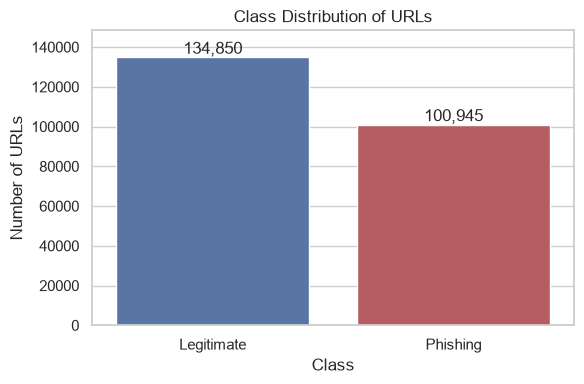

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
class_labels = df["label"].map(LABEL_NAMES)
sns.countplot(x=class_labels, hue=class_labels, order=["Legitimate", "Phishing"], palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")

ax.margins(y=0.1)
ax.set_title("Class Distribution of URLs")
ax.set_xlabel("Class")
ax.set_ylabel("Number of URLs")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "class_distribution.png", dpi=300)
plt.show()

### Findings: Class Distribution

- The dataset contains **134,850 legitimate URLs (57.19%)** and **100,945 phishing URLs (42.81%)**.
- The label encoding is **1 = Legitimate** and **0 = Phishing**.
- The class ratio is approximately **57:43**, so the dataset is **reasonably balanced** and does not require resampling techniques such as SMOTE.
- A **stratified train-test split** will still be used to preserve this ratio in both sets.
- Since a model predicting only "Legitimate" would already achieve ~57% accuracy, models will be evaluated using **Precision, Recall and F1-score** in addition to accuracy.

## 4. Feature Correlation with Target

In [12]:
numeric_df = df.drop(columns=text_cols)
target_corr = numeric_df.corr()["label"].drop("label").sort_values(key=abs, ascending=False)
target_corr.head(15)

URLSimilarityIndex       0.860
HasSocialNet             0.784
HasCopyrightInfo         0.743
HasDescription           0.690
IsHTTPS                  0.609
DomainTitleMatchScore    0.585
HasSubmitButton          0.579
IsResponsive             0.549
URLTitleMatchScore       0.539
SpacialCharRatioInURL   -0.534
HasHiddenFields          0.508
HasFavicon               0.494
URLCharProb              0.470
CharContinuationRate     0.468
HasTitle                 0.460
Name: label, dtype: float64

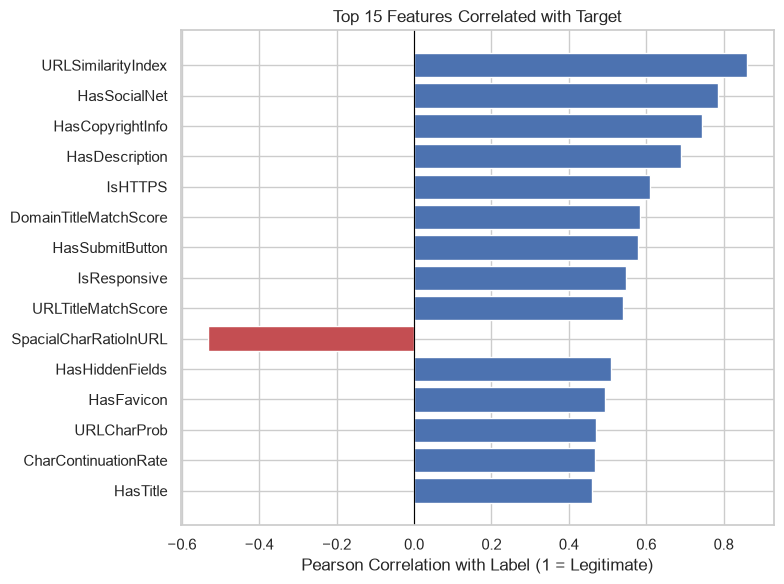

In [13]:
top_corr = target_corr.head(15)
colors = ["#4C72B0" if value > 0 else "#C44E52" for value in top_corr]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_corr.index[::-1], top_corr.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top 15 Features Correlated with Target")
ax.set_xlabel("Pearson Correlation with Label (1 = Legitimate)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "feature_correlation.png", dpi=300)
plt.show()

### Findings: Feature Correlation

- **`URLSimilarityIndex`** shows the strongest correlation with the target (**0.86**), making it the most informative single feature.
- Page-content features such as **`HasSocialNet`** (0.78), **`HasCopyrightInfo`** (0.74) and **`HasDescription`** (0.69) are strongly associated with legitimate websites.
- **`IsHTTPS`** (0.61) indicates that legitimate URLs are more likely to use secure HTTPS connections.
- **`SpacialCharRatioInURL`** (-0.53) is the strongest negative feature, meaning URLs with a higher ratio of special characters are more likely to be phishing.
- Several features have very high correlation with the target, so very high model accuracy is expected. Model results will be interpreted with this in mind.

## 5. Descriptive Statistics

In [14]:
numeric_cols = df.select_dtypes(include="number").columns.drop("label")

binary_cols = [col for col in numeric_cols if df[col].nunique() == 2]
continuous_cols = [col for col in numeric_cols if df[col].nunique() > 2]
constant_cols = [col for col in numeric_cols if df[col].nunique() <= 1]

print(f"Numeric features: {len(numeric_cols)}")
print(f"Binary features (0/1): {len(binary_cols)}")
print(f"Continuous features: {len(continuous_cols)}")
print(f"Constant features: {len(constant_cols)} {constant_cols}")

Numeric features: 50
Binary features (0/1): 19
Continuous features: 31
Constant features: 0 []


In [15]:
desc = df[continuous_cols].describe().T
desc["range"] = desc["max"] - desc["min"]
desc.sort_values("range", ascending=False).round(3)

,count,mean,std,min,25%,50%,75%,max,range
LargestLineLength,"235,795.000","12,789.533","152,201.099",22.000,200.000,"1,090.000","8,047.000","13,975,732.000","13,975,710.000"
LineOfCode,"235,795.000","1,141.900","3,419.951",2.000,18.000,429.000,"1,277.000","442,666.000","442,664.000"
NoOfCSS,"235,795.000",6.333,74.866,0.000,0.000,2.000,8.000,"35,820.000","35,820.000"
NoOfExternalRef,"235,795.000",49.263,161.027,0.000,1.000,10.000,57.000,"27,516.000","27,516.000"
NoOfSelfRef,"235,795.000",65.071,176.688,0.000,0.000,12.000,88.000,"27,397.000","27,397.000"
NoOfImage,"235,795.000",26.076,79.412,0.000,0.000,8.000,29.000,"8,956.000","8,956.000"
NoOfJS,"235,795.000",10.522,22.312,0.000,0.000,6.000,15.000,"6,957.000","6,957.000"
URLLength,"235,795.000",34.573,41.314,13.000,23.000,27.000,34.000,"6,097.000","6,084.000"
NoOfLettersInURL,"235,795.000",19.429,29.090,0.000,10.000,14.000,20.000,"5,191.000","5,191.000"
NoOfEmptyRef,"235,795.000",2.378,17.641,0.000,0.000,0.000,1.000,"4,887.000","4,887.000"


In [16]:
skewness = df[continuous_cols].skew().sort_values(ascending=False)
highly_skewed = skewness[skewness.abs() > 1]
print(f"Highly skewed features (|skew| > 1): {len(highly_skewed)} of {len(continuous_cols)}")
highly_skewed.round(2)

Highly skewed features (|skew| > 1): 26 of 31


NoOfCSS                      464.400
NoOfObfuscatedChar           204.680
NoOfJS                       140.440
NoOfEqualsInURL              114.990
NoOfEmptyRef                 106.830
NoOfAmpersandInURL           106.720
NoOfiFrame                    97.680
NoOfDegitsInURL               94.880
NoOfPopup                     84.950
NoOfExternalRef               65.900
NoOfSelfRef                   60.380
NoOfLettersInURL              58.400
URLLength                     53.320
LineOfCode                    53.070
LargestLineLength             48.180
NoOfOtherSpecialCharsInURL    47.430
ObfuscationRatio              40.120
NoOfImage                     28.230
NoOfQMarkInURL                 8.160
DegitRatioInURL                3.240
DomainLength                   2.510
NoOfSubDomain                  1.810
TLDLength                      1.660
SpacialCharRatioInURL          1.180
URLCharProb                   -1.060
CharContinuationRate          -1.130
dtype: float64

### Findings: Descriptive Statistics

- The dataset has **50 numeric features**: **19 binary** and **31 continuous**. No constant features were found.
- Feature ranges vary dramatically, from `TLDLegitimateProb` (0 – 0.52) to `LargestLineLength` (22 – 13,975,730), so **feature scaling is required** for distance- and gradient-based models (Logistic Regression, KNN, SVM).
- **26 of the 31 continuous features are highly skewed** (|skew| > 1). Extreme examples include `NoOfCSS` (464.4), `NoOfObfuscatedChar` (204.7) and `NoOfJS` (140.4).
- Many count features have a **median of 0** with a small number of extremely large values (e.g. `LargestLineLength` has a mean of 12,790 but a median of only 1,090).
- These outliers are treated as **genuine observations**, not errors, since phishing and legitimate web pages can naturally differ greatly in size and structure. They will therefore be retained.
- A **log transformation (`log1p`)** will be applied to highly skewed features for scale-sensitive models, while tree-based models will use the original values.

## 6. Feature Distributions by Class

In [17]:
top_continuous = target_corr[target_corr.index.isin(continuous_cols)].head(6).index.tolist()
top_continuous

['URLSimilarityIndex',
 'DomainTitleMatchScore',
 'URLTitleMatchScore',
 'SpacialCharRatioInURL',
 'URLCharProb',
 'CharContinuationRate']

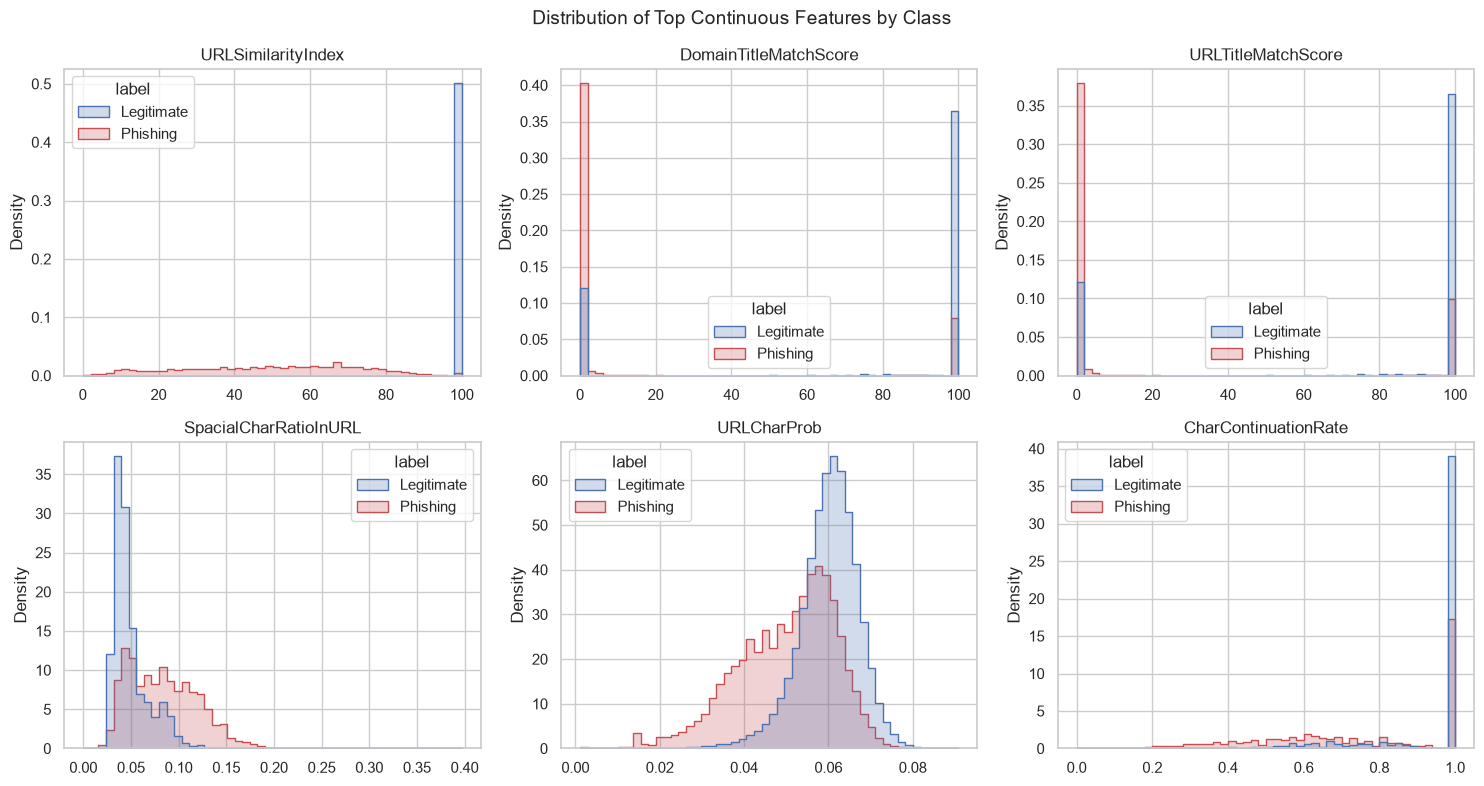

In [18]:
class_labels = df["label"].map(LABEL_NAMES)
class_palette = {"Legitimate": "#4C72B0", "Phishing": "#C44E52"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, top_continuous):
    sns.histplot(x=df[col], hue=class_labels, bins=50, stat="density", common_norm=False, element="step", palette=class_palette, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")

fig.suptitle("Distribution of Top Continuous Features by Class", fontsize=14)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "continuous_feature_distributions.png", dpi=300)
plt.show()

In [19]:
top_binary = target_corr[target_corr.index.isin(binary_cols)].head(8).index.tolist()
binary_rates = df.groupby(class_labels)[top_binary].mean().T * 100
binary_rates.round(1)

label,Legitimate,Phishing
HasSocialNet,79.500,0.500
HasCopyrightInfo,80.800,5.700
HasDescription,73.700,4.400
IsHTTPS,100.000,49.200
HasSubmitButton,66.100,8.500
IsResponsive,85.400,31.700
HasHiddenFields,59.100,9.300
HasFavicon,56.700,8.800


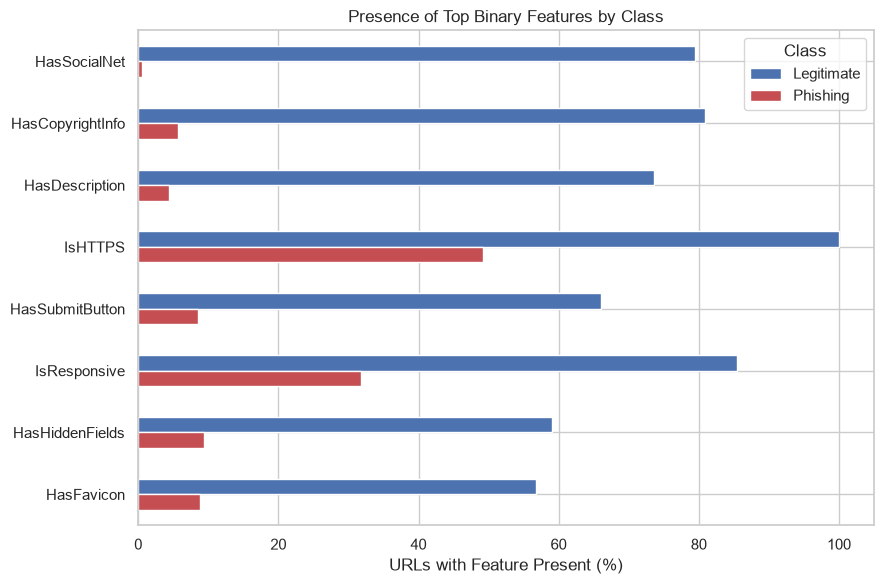

In [22]:
ax = binary_rates.plot(kind="barh", figsize=(9, 6), color=[class_palette["Legitimate"], class_palette["Phishing"]])
ax.set_title("Presence of Top Binary Features by Class")
ax.set_xlabel("URLs with Feature Present (%)")
ax.get_legend().set_title("Class")
ax.set_ylabel("")
ax.legend(title="Class")
ax.invert_yaxis()

fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "binary_feature_presence.png", dpi=300)
plt.show()

### Findings: Feature Distributions by Class

- **`URLSimilarityIndex`** almost perfectly separates the classes: virtually all legitimate URLs have a value of **100**, while phishing URLs are spread across the full 0–100 range.
- **`DomainTitleMatchScore`** and **`URLTitleMatchScore`** are strongly bimodal: phishing pages mostly score **0**, while legitimate pages mostly score **100**, indicating that phishing page titles rarely match their domain.
- Phishing URLs have a **higher special-character ratio** and a **lower `URLCharProb`**, although these features show some overlap between classes.
- Among binary features, **`HasSocialNet`** is the strongest indicator: present in **79.5%** of legitimate pages but only **0.5%** of phishing pages.
- **All legitimate URLs use HTTPS (100%)**, but **49.2% of phishing URLs also use HTTPS**, showing that HTTPS alone is not a reliable indicator of a safe website.
- Page-content features (social links, copyright info, descriptions) are highly discriminative, which explains the strong correlations observed in Section 4.